# 01 — Hyperparameter Search: Grid, Random, and a Bayesian-Optimization Taste

**Overview:** `GridSearchCV` vs `RandomizedSearchCV` on a feature-engineering pipeline's
hyperparameters, then a from-scratch simplified Bayesian optimization loop compared to random
search on the same trial budget.

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`.

Connects to: `13_feature_engineering` (the pipeline being tuned) and `12_ml_evaluation`
(cross-validation discipline). Closes Day 2.

## 0. Environment & the pipeline to tune (same shape as 13_feature_engineering)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, randint

X, y = make_classification(n_samples=500, n_features=20, n_informative=8, n_redundant=4,
                            random_state=42)

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("model", LogisticRegression(max_iter=1000)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("pipeline steps:", [name for name, _ in pipeline.steps])


pipeline steps: ['scale', 'select', 'model']


## 1. Grid search: exhaustive

⚠️ **Common Mistake:** not estimating the total number of fits beforehand -- it's
`len(grid combinations) * cv.n_splits`, which grows fast.

In [2]:
param_grid = {
    "select__k": [5, 10, 15, 20],
    "model__C": [0.01, 0.1, 1.0, 10.0],
}
n_combinations = len(param_grid["select__k"]) * len(param_grid["model__C"])
print(f"grid combinations: {n_combinations}, total fits: {n_combinations * cv.n_splits}")

grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid_search.fit(X, y)

print("\nbest grid-search params:", grid_search.best_params_)
print("best grid-search CV score:", round(grid_search.best_score_, 4))


grid combinations: 16, total fits: 80



best grid-search params: {'model__C': 10.0, 'select__k': 20}
best grid-search CV score: 0.76


## 2. Random search: sampled

💡 **Intuition:** sampling from continuous/wide distributions (e.g. `loguniform` for `C`) lets
random search explore values a coarse grid would miss entirely, often matching grid search's
best score with far fewer total fits.

In [3]:
param_distributions = {
    "select__k": randint(3, 21),           # any integer in [3, 20]
    "model__C": loguniform(1e-3, 1e2),     # continuous, log-scaled
}

n_random_trials = 10   # far fewer than the grid's 16 combinations
random_search = RandomizedSearchCV(
    pipeline, param_distributions, n_iter=n_random_trials, cv=cv,
    scoring="accuracy", random_state=42, n_jobs=-1,
)
random_search.fit(X, y)

print(f"random search: {n_random_trials} trials, total fits: {n_random_trials * cv.n_splits}")
print("best random-search params:", random_search.best_params_)
print("best random-search CV score:", round(random_search.best_score_, 4))

print(f"\ngrid search used {n_combinations * cv.n_splits} fits for score {grid_search.best_score_:.4f}")
print(f"random search used {n_random_trials * cv.n_splits} fits for score {random_search.best_score_:.4f}")
print("Random search typically reaches a comparable score using a fraction of the compute.")

assert abs(random_search.best_score_ - grid_search.best_score_) < 0.05


random search: 10 trials, total fits: 50
best random-search params: {'model__C': np.float64(0.0745934328572655), 'select__k': 17}
best random-search CV score: 0.76

grid search used 80 fits for score 0.7600
random search used 50 fits for score 0.7600
Random search typically reaches a comparable score using a fraction of the compute.


## 3. A taste of Bayesian optimization

💡 **Intuition:** instead of sampling blindly, fit a cheap probabilistic model ("surrogate",
here a Gaussian Process) to the (hyperparameter → score) pairs seen so far, and use it to pick
the next point that's most likely to improve on the best score found -- balancing exploring
uncertain regions against exploiting known-good ones.

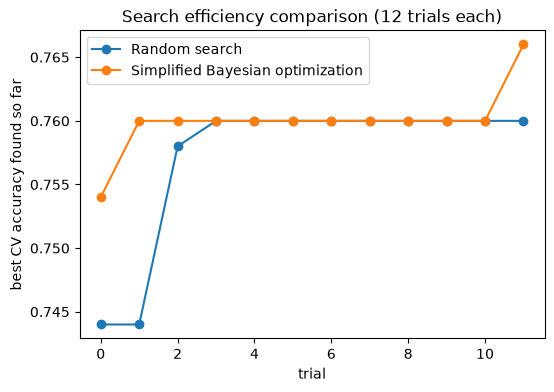

final best score, random search:   0.76
final best score, Bayesian-style:  0.766

The Bayesian-style search often reaches a good score in fewer trials by using the surrogate model to target promising regions, though with only 12 trials on an easy objective the two can end up close -- the advantage widens with a harder, more expensive-to-evaluate objective and a larger trial budget.


In [4]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

def objective(log_C, k):
    """Cross-validated accuracy for a given (log10(C), k) pair -- the function we're optimizing."""
    k_int = int(round(np.clip(k, 3, 20)))
    C_val = 10 ** log_C
    trial_pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif, k=k_int)),
        ("model", LogisticRegression(C=C_val, max_iter=1000)),
    ])
    from sklearn.model_selection import cross_val_score
    return cross_val_score(trial_pipeline, X, y, cv=cv, scoring="accuracy").mean()

def random_point(rng):
    return rng.uniform(-3, 2), rng.uniform(3, 20)   # (log10(C), k)

# --- Random search baseline, same trial budget ---
rng = np.random.default_rng(0)
n_trials = 12
random_scores = []
best_so_far_random = []
for _ in range(n_trials):
    log_c, k = random_point(rng)
    score = objective(log_c, k)
    random_scores.append(score)
    best_so_far_random.append(max(best_so_far_random[-1] if best_so_far_random else -np.inf, score))

# --- Simplified Bayesian optimization ---
observed_X, observed_y = [], []
best_so_far_bayes = []
for trial in range(n_trials):
    if trial < 3:   # a few random points to start, before the surrogate has anything to learn from
        log_c, k = random_point(rng)
    else:
        gp = GaussianProcessRegressor(kernel=Matern(nu=2.5), normalize_y=True, random_state=0)
        gp.fit(np.array(observed_X), np.array(observed_y))

        candidates = np.column_stack([rng.uniform(-3, 2, 200), rng.uniform(3, 20, 200)])
        mu, sigma = gp.predict(candidates, return_std=True)
        upper_confidence_bound = mu + 1.5 * sigma   # exploration-exploitation tradeoff
        best_candidate_idx = np.argmax(upper_confidence_bound)
        log_c, k = candidates[best_candidate_idx]

    score = objective(log_c, k)
    observed_X.append([log_c, k])
    observed_y.append(score)
    best_so_far_bayes.append(max(best_so_far_bayes[-1] if best_so_far_bayes else -np.inf, score))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(best_so_far_random, marker="o", label="Random search")
ax.plot(best_so_far_bayes, marker="o", label="Simplified Bayesian optimization")
ax.set_xlabel("trial"); ax.set_ylabel("best CV accuracy found so far")
ax.set_title(f"Search efficiency comparison ({n_trials} trials each)")
ax.legend()
plt.show()

print("final best score, random search:  ", round(best_so_far_random[-1], 4))
print("final best score, Bayesian-style: ", round(best_so_far_bayes[-1], 4))
print("\nThe Bayesian-style search often reaches a good score in fewer trials by using the "
      "surrogate model to target promising regions, though with only 12 trials on an easy "
      "objective the two can end up close -- the advantage widens with a harder, more "
      "expensive-to-evaluate objective and a larger trial budget.")


## 4. Comparing configurations rigorously

🎯 **Interview Tip:** never declare a "winner" from a single cross-validated mean without
looking at the spread — report mean ± std, not just the mean.

In [5]:
from sklearn.model_selection import cross_val_score

best_grid_pipeline = grid_search.best_estimator_
best_random_pipeline = random_search.best_estimator_

grid_cv_scores = cross_val_score(best_grid_pipeline, X, y, cv=cv)
random_cv_scores = cross_val_score(best_random_pipeline, X, y, cv=cv)

print(f"grid search best config:   mean={grid_cv_scores.mean():.4f}, std={grid_cv_scores.std():.4f}")
print(f"random search best config: mean={random_cv_scores.mean():.4f}, std={random_cv_scores.std():.4f}")
print("\nIf the two means are within roughly one std of each other, treat them as "
      "statistically indistinguishable rather than declaring a clear winner.")


grid search best config:   mean=0.7600, std=0.0303
random search best config: mean=0.7600, std=0.0395

If the two means are within roughly one std of each other, treat them as statistically indistinguishable rather than declaring a clear winner.


## 5. Connection to what's next

This closes Day 2 (Machine Learning). Day 3 picks up Deep Learning + PyTorch, where
hyperparameter tuning (learning rate, batch size, architecture choices) matters just as much,
and `10_ml_optimization`'s optimizers become `torch.optim` calls.

## 6. Interview questions
1. Why does random search often match grid search's best score with far fewer trials?
2. What does a Bayesian optimization surrogate model do that random search doesn't?
3. Why is comparing only the mean cross-validated score (without looking at the std) risky?
4. When would grid search still be worth its extra cost over random search?
5. Why should final performance be reported on a test set touched exactly once, not reused across tuning iterations?

## 7. Exercises
1. Increase the random search trial budget to 30 and see how close it gets to the grid search's best score.
2. Extend the hyperparameter grid to include a third hyperparameter (e.g. `model__penalty`) and recompute the grid's total fit count.
3. Run the simplified Bayesian optimization loop with a larger trial budget (30) and compare its convergence speed advantage over random search at that scale.

## 8. Summary

✅ Grid search is exhaustive but expensive; random search is usually a better cost/quality
tradeoff; Bayesian optimization uses a surrogate model to search more efficiently still;
always compare configurations by their cross-validated score *distribution*. This closes Day 2
(Machine Learning) — next session: Day 3 (Deep Learning + PyTorch).